# Flight-Delay: SQL analysis

This notebook loads the cleaned sample (`data/flights_clean.parquet`) into DuckDB and uses SQL to compare the delay rate (share of flights with `delayed` = 1) by airline, departure hour and origin airport.

## Setup

Installs `matplotlib` and `duckdb`, imports them with `numpy`, and opens a connection `con` to `data/flights.duckdb`.

In [83]:
%pip install matplotlib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [85]:
%pip install duckdb

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [111]:
import matplotlib.pyplot as plt
import numpy as np

In [86]:
import duckdb
con = duckdb.connect("data/flights.duckdb")

## Load the table

The first cell below opens a second connection to the same file without assigning it, so it only displays the connection object. The `CREATE TABLE` cell raised an error because `flight_data` already exists in `data/flights.duckdb`, so the queries below use that existing table. The `COUNT (*)` cell displays the connection object rather than the count because the result is not fetched.

In [87]:
duckdb.connect("data/flights.duckdb")

In [88]:
con.execute('''CREATE TABLE flight_data AS SELECT * FROM read_parquet('data/flights_clean.parquet')''');

CatalogException: Catalog Error: Table with name "flight_data" already exists!

In [89]:
con.execute('''SELECT COUNT (*) FROM flight_data''')

## Delay rate by airline

Groups flights by `Reporting_Airline` and sorts by delay rate, highest first. The `assert` checks that the airline counts add up to 48,374 flights, and it passed. B6 has the highest rate (0.374) and MQ the lowest (0.184).

In [90]:
new_table = con.execute('''SELECT Reporting_Airline, COUNT(*) AS num_flights, AVG(delayed) AS
     avg_delay_rate FROM flight_data GROUP BY Reporting_Airline ORDER BY avg_delay_rate DESC''').df()
display(new_table)
assert(new_table['num_flights'].sum() == 48374)


,Reporting_Airline,num_flights,avg_delay_rate
0,B6,1679,0.374032
1,OH,1575,0.356825
2,F9,1578,0.347909
3,AA,6762,0.323869
4,G4,1062,0.306968
5,WN,9867,0.294517
6,DL,7242,0.257111
7,YX,2329,0.247316
8,UA,5678,0.244452
9,OO,5837,0.226658


### Delay rate by airline chart

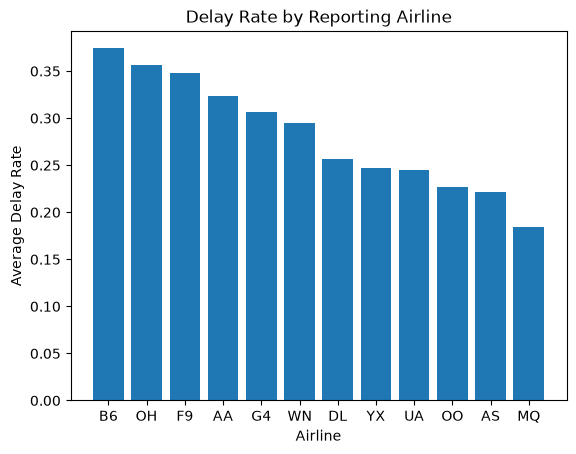

In [139]:
plt.bar(new_table['Reporting_Airline'], new_table['avg_delay_rate'])
plt.title('Delay Rate by Reporting Airline')
plt.xlabel('Airline')
plt.ylabel('Average Delay Rate')
plt.savefig("plots/delay_by_airline.png")
plt.show()

## Delay rate by departure hour

Are flights delayed more often in the morning or at night?

In [93]:
hourly_delayed_flights = con.execute('''SELECT dep_hour, AVG(delayed) AS avg_delay_rate, COUNT(*) AS num_flights FROM flight_data GROUP BY dep_hour ORDER BY dep_hour''').df()
display(hourly_delayed_flights)

,dep_hour,avg_delay_rate,num_flights
0,0,0.293333,75
1,1,0.217391,23
2,2,0.000000,8
3,3,0.166667,6
4,4,0.000000,1
5,5,0.080163,1472
6,6,0.098655,3345
7,7,0.128057,3639
8,8,0.143844,3184
9,9,0.168605,2752


Delay rates do seem to climb through the day reaching a peak around 8PM then they start to die down.

### Delay rate by hour chart

The red line is the delay rate per hour. Black points mark hours with fewer than 100 flights (hours 0–4).

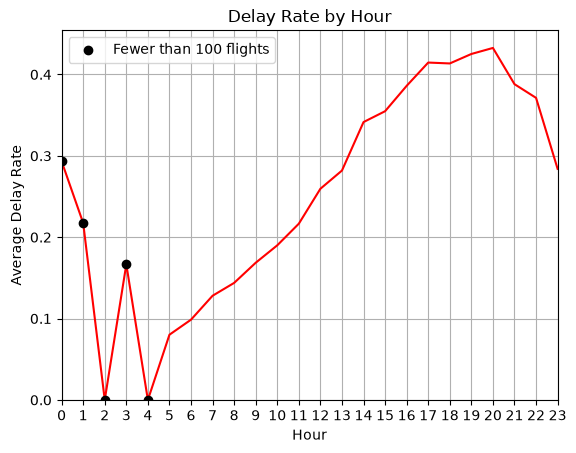

In [143]:
plt.plot(hourly_delayed_flights['dep_hour'], hourly_delayed_flights['avg_delay_rate'], color = 'red')
thin = hourly_delayed_flights[hourly_delayed_flights['num_flights'] < 100]
plt.scatter(thin['dep_hour'], thin['avg_delay_rate'], color='black', zorder=3, label='Fewer than 100 flights')
plt.legend()
plt.title('Delay Rate by Hour')
plt.xlabel('Hour')
plt.ylabel('Average Delay Rate')
plt.grid(True)
plt.xticks(np.arange(0, 24, 1))
plt.xlim(left=0, right=23)
plt.ylim(bottom=0.0)
plt.savefig("plots/delay_by_hour.png")
plt.show()
# overnight hours are kinda weird looking

## Delay rate by origin airport

Do some airports have more late flights than others?

Only airports with more than 99 flights are kept (`HAVING num_flights > 99`), sorted by delay rate, lowest first. 89 airports pass the filter and together cover 42,990 of 48,374 flights (~89%). The `42990 / 48374` line does not display a result because it isn't the last line of the cell. The lowest rates are LIH, KOA, ANC, OGG and OMA, and the highest are FLL, BNA, CLT, MIA and DCA.

In [130]:
airports_by_delay_rate = con.execute('''SELECT Origin, COUNT(*) AS num_flights, AVG(delayed) AS avg_delayed_rate FROM flight_data GROUP BY Origin HAVING num_flights > 99 ORDER BY avg_delayed_rate ASC''').df()
display(airports_by_delay_rate)
print(airports_by_delay_rate['num_flights'].sum())
42990 / 48374 #~89% of flights survived.
display(airports_by_delay_rate.head())
display(airports_by_delay_rate.tail())
# We can see that bigger airports had a higher avg delay rate


,Origin,num_flights,avg_delayed_rate
0,LIH,122,0.122951
1,KOA,102,0.127451
2,ANC,190,0.142105
3,OGG,186,0.145161
4,OMA,190,0.152632
...,...,...,...
84,FLL,535,0.353271
85,BNA,791,0.356511
86,CLT,1131,0.358090
87,MIA,683,0.368960


42990


,Origin,num_flights,avg_delayed_rate
0,LIH,122,0.122951
1,KOA,102,0.127451
2,ANC,190,0.142105
3,OGG,186,0.145161
4,OMA,190,0.152632


,Origin,num_flights,avg_delayed_rate
84,FLL,535,0.353271
85,BNA,791,0.356511
86,CLT,1131,0.358090
87,MIA,683,0.368960
88,DCA,932,0.383047


# Findings

Results come from a 50,000-flight random sample of July 2026 BTS data. A flight counts as delayed if it arrived more than 15 minutes late. Cancelled and diverted flights are excluded.

**Airline:** B6 had the highest delay rate (37.4%, 1,679 flights) and MQ the lowest (18.4%, 2,328 flights), a gap of 19.0 percentage points.

**Airport:** Among airports with at least 100 flights, the 5 highest delay rates all belonged to airports with over 500 flights, and the 5 lowest to airports with under 200. This suggests larger airports run later, but I have not tested it beyond these extremes.

**Hour:** The delay rate generally rises from about 5 AM to 8 PM, then declines. Hours 0 to 4 have fewer than 100 flights, so their rates are too noisy to interpret and are marked on the chart.